In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option('display.max_columns', None)


sns.set_style('whitegrid')

In [2]:
# Loading the datasets

hour_df = pd.read_csv('hour.csv')

print("Hourly Dataset Shape:", hour_df.shape)


Hourly Dataset Shape: (17379, 17)


In [ ]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [ ]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [ ]:
# Checking missing values
print(hour_df.isnull().sum())


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [ ]:
# Checking duplicated rows
print("Number of duplicates:", hour_df.duplicated().sum())

Number of duplicates: 0


In [ ]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


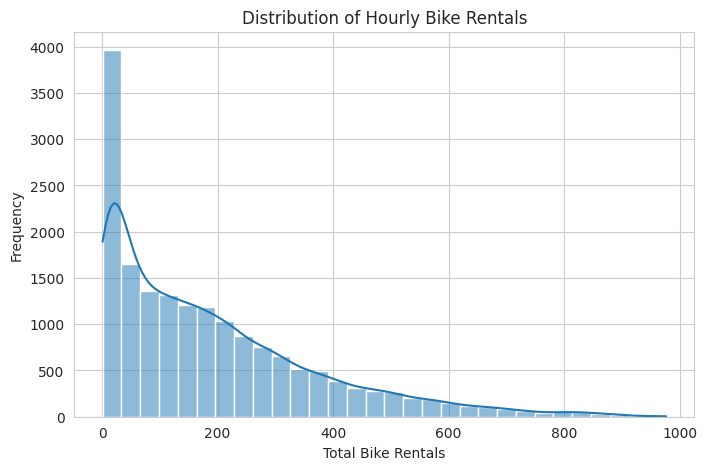

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=hour_df, x='cnt', bins=30, kde=True)

plt.title('Distribution of Hourly Bike Rentals')
plt.xlabel('Total Bike Rentals')
plt.ylabel('Frequency')

plt.show()

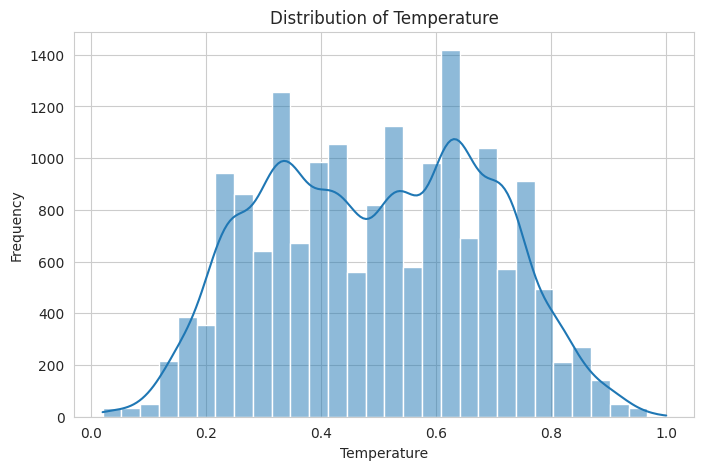

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=hour_df, x='temp', bins=30, kde=True)

plt.title('Distribution of Temperature')
plt.xlabel('Temperature')
plt.ylabel('Frequency')

plt.show()

In [ ]:
# Correlation Analysis

columns_to_drop = ['instant', 'casual', 'registered', 'dteday']

correlation_df = hour_df.drop(columns=columns_to_drop)

correlation_matrix = correlation_df.corr(method='pearson')

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
season,1.000000,-0.010742,0.830386,-0.006117,-0.009585,-0.002335,0.013743,-0.014524,0.312025,0.319380,0.150625,-0.149773,0.178056
yr,-0.010742,1.000000,-0.010473,-0.003867,0.006692,-0.004485,-0.002196,-0.019157,0.040913,0.039222,-0.083546,-0.008740,0.250495
mnth,0.830386,-0.010473,1.000000,-0.005772,0.018430,0.010400,-0.003477,0.005400,0.201691,0.208096,0.164411,-0.135386,0.120638
hr,-0.006117,-0.003867,-0.005772,1.000000,0.000479,-0.003498,0.002285,-0.020203,0.137603,0.133750,-0.276498,0.137252,0.394071
holiday,-0.009585,0.006692,0.018430,0.000479,1.000000,-0.102088,-0.252471,-0.017036,-0.027340,-0.030973,-0.010588,0.003988,-0.030927
weekday,-0.002335,-0.004485,0.010400,-0.003498,-0.102088,1.000000,0.035955,0.003311,-0.001795,-0.008821,-0.037158,0.011502,0.026900
workingday,0.013743,-0.002196,-0.003477,0.002285,-0.252471,0.035955,1.000000,0.044672,0.055390,0.054667,0.015688,-0.011830,0.030284
weathersit,-0.014524,-0.019157,0.005400,-0.020203,-0.017036,0.003311,0.044672,1.000000,-0.102640,-0.105563,0.418130,0.026226,-0.142426
temp,0.312025,0.040913,0.201691,0.137603,-0.027340,-0.001795,0.055390,-0.102640,1.000000,0.987672,-0.069881,-0.023125,0.404772
atemp,0.319380,0.039222,0.208096,0.133750,-0.030973,-0.008821,0.054667,-0.105563,0.987672,1.000000,-0.051918,-0.062336,0.400929


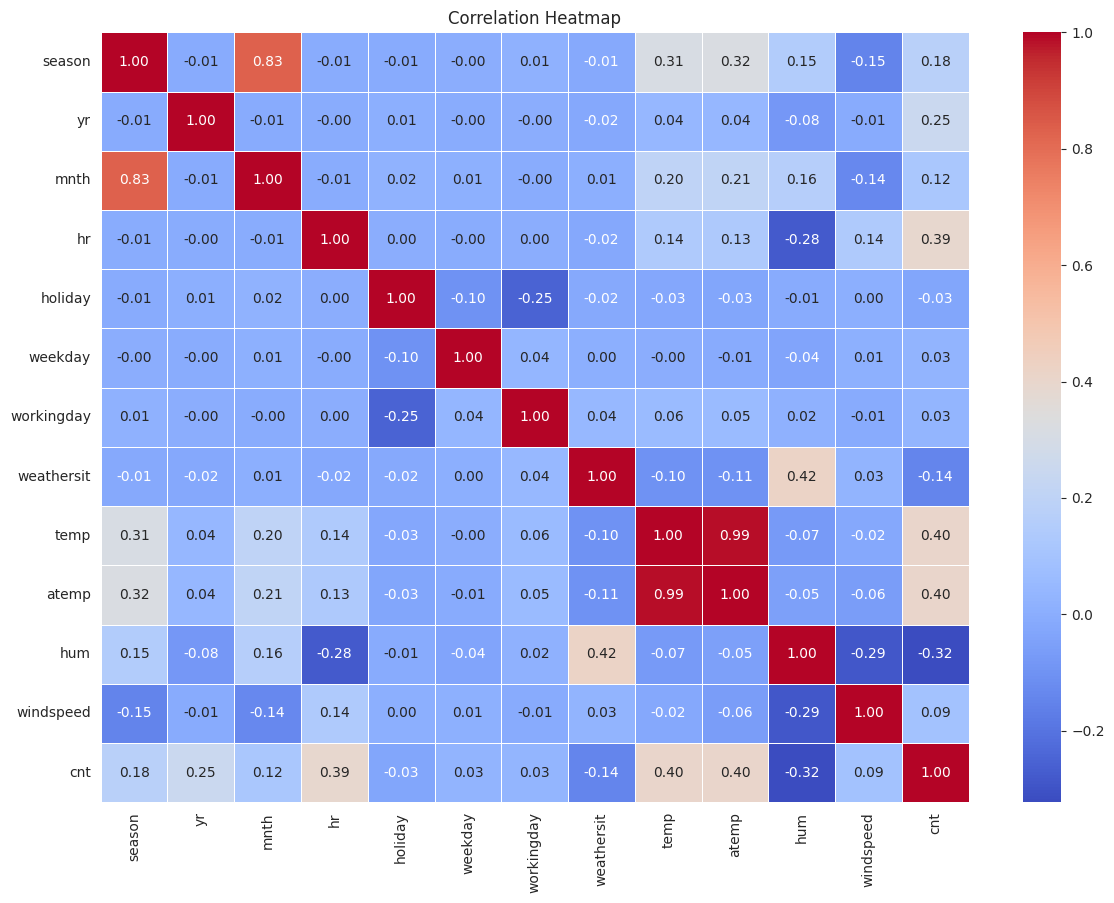

In [ ]:
# Correlation Heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
# Correlation with Target Variable

target_correlation = correlation_matrix['cnt'].drop('cnt')

target_correlation = target_correlation.sort_values(
    ascending=False
)

print("Correlation with Bike Rentals (cnt):")
display(target_correlation)

Correlation with Bike Rentals (cnt):


,cnt
temp,0.404772
atemp,0.400929
hr,0.394071
yr,0.250495
season,0.178056
mnth,0.120638
windspeed,0.093234
workingday,0.030284
weekday,0.026900
holiday,-0.030927


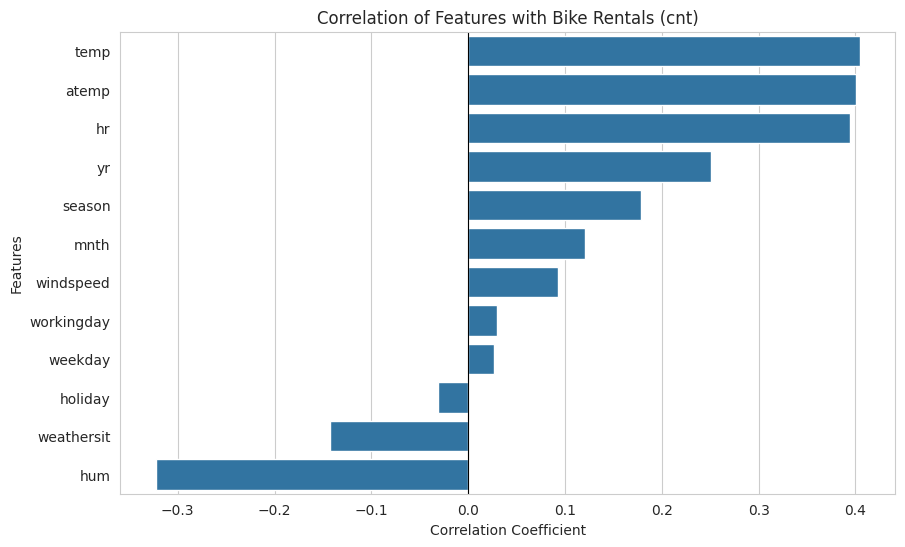

In [ ]:
# Visualizing Feature Correlation with Target

plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_correlation.values,
    y=target_correlation.index
)

plt.title('Correlation of Features with Bike Rentals (cnt)')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.axvline(x=0, color='black', linewidth=0.8)

plt.show()

In [ ]:
# Reviewing Features for Model Building

excluded_features = ['instant', 'casual', 'registered', 'dteday']

selected_features = [
    col for col in hour_df.columns
    if col not in excluded_features + ['cnt']
]

print("Selected Features:")
print(selected_features)

print("\nExcluded Features:")
print(excluded_features)

Selected Features:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']

Excluded Features:
['instant', 'casual', 'registered', 'dteday']


In [3]:
features = [
    'yr', 'mnth', 'hr', 'holiday', 'weekday',
    'workingday', 'weathersit', 'temp', 'hum', 'windspeed'
]

X = hour_df[features]
y = hour_df['cnt']

In [4]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())

Features shape: (17379, 10)
Target shape: (17379,)

Features:
   yr  mnth  hr  holiday  weekday  workingday  weathersit  temp   hum  \
0   0     1   0        0        6           0           1  0.24  0.81   
1   0     1   1        0        6           0           1  0.22  0.80   
2   0     1   2        0        6           0           1  0.22  0.80   
3   0     1   3        0        6           0           1  0.24  0.75   
4   0     1   4        0        6           0           1  0.24  0.75   

   windspeed  
0        0.0  
1        0.0  
2        0.0  
3        0.0  
4        0.0  

Target:
0    16
1    40
2    32
3    13
4     1
Name: cnt, dtype: int64


In [5]:
X.dtypes

,0
yr,int64
mnth,int64
hr,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64
temp,float64
hum,float64
windspeed,float64


In [6]:
from sklearn.model_selection import train_test_split

# Split the data into training and temporary sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split the temporary set into validation and testing sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

In [7]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (12165, 10)
Validation: (2607, 10)
Testing: (2607, 10)


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ['mnth', 'hr', 'weekday', 'weathersit']

numerical_features = ['temp', 'hum', 'windspeed']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ],
    remainder='passthrough'
)

In [9]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

In [10]:
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (12165, 53)
Validation: (2607, 53)
Testing: (2607, 53)


In [11]:
print("Training X:", X_train_processed.shape)
print("Training y:", y_train.shape)

print("Validation X:", X_val_processed.shape)
print("Validation y:", y_val.shape)

print("Testing X:", X_test_processed.shape)
print("Testing y:", y_test.shape)

Training X: (12165, 53)
Training y: (12165,)
Validation X: (2607, 53)
Validation y: (2607,)
Testing X: (2607, 53)
Testing y: (2607,)


In [12]:
import joblib

In [13]:
preprocessed_data = {
    'X_train': X_train_processed,
    'X_val': X_val_processed,
    'X_test': X_test_processed,
    'y_train': y_train,
    'y_val': y_val,
    'y_test': y_test,
    'preprocessor': preprocessor
}

In [14]:
joblib.dump(preprocessed_data, 'preprocessed_data.joblib')

['preprocessed_data.joblib']

In [15]:
import os

print(os.path.exists('preprocessed_data.joblib'))

True


In [16]:
from google.colab import files

files.download('preprocessed_data.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>